# Processamento de Imagens — Aula 4

**Conteúdo:** imagens de exemplo da biblioteca scikit-image, visualização de coleções e aplicação de filtros espaciais usando OpenCV.

*Numeração provisória: primeira branch de aula livre no repositório.*

## Bibliotecas

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

## Imagens de exemplo da scikit-image

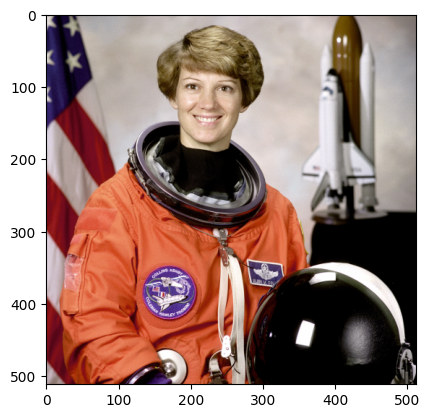

In [ ]:
plt.imshow(data.astronaut())

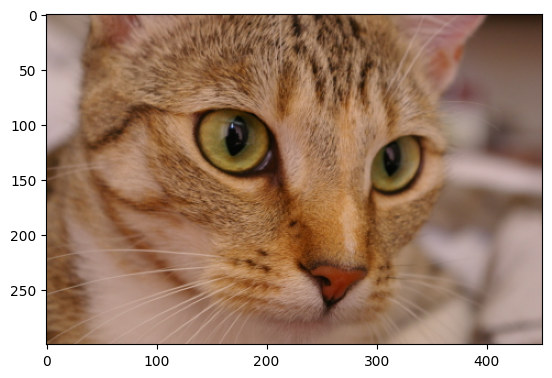

In [ ]:
plt.imshow(data.cat())

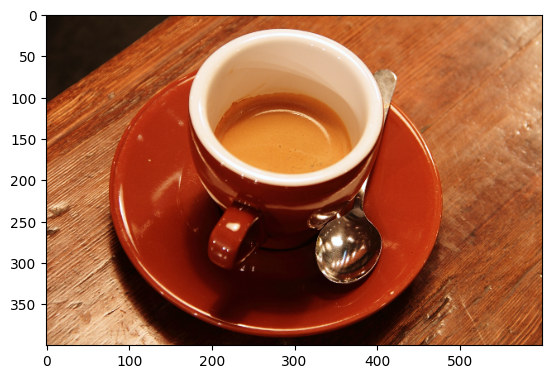

In [ ]:
plt.imshow(data.coffee())

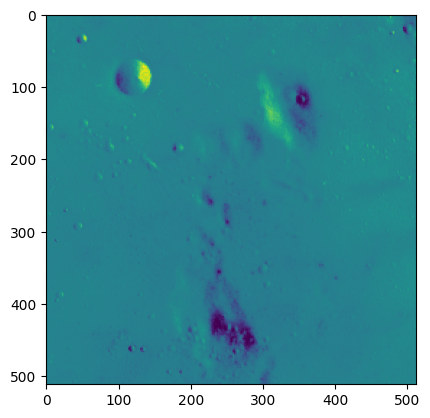

In [ ]:
plt.imshow(data.moon())

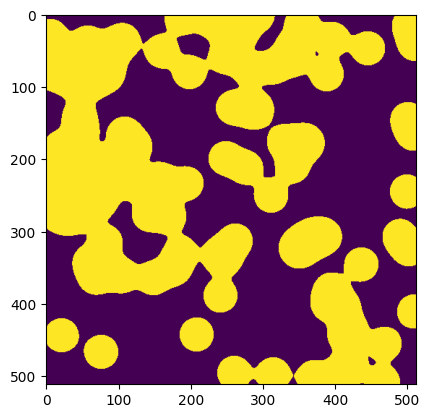

In [ ]:
plt.imshow(data.binary_blobs())

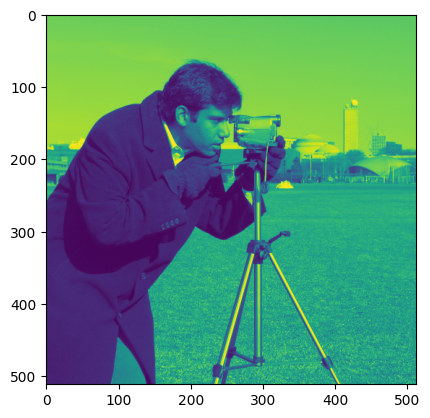

In [ ]:
plt.imshow(data.camera())

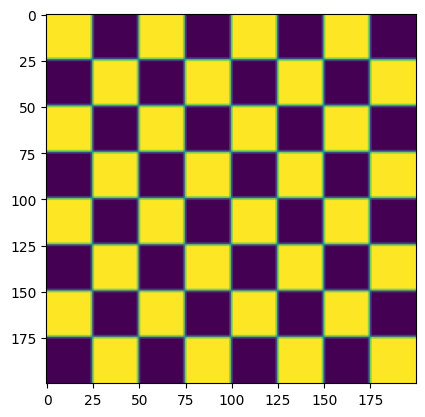

In [ ]:
plt.imshow(data.checkerboard())

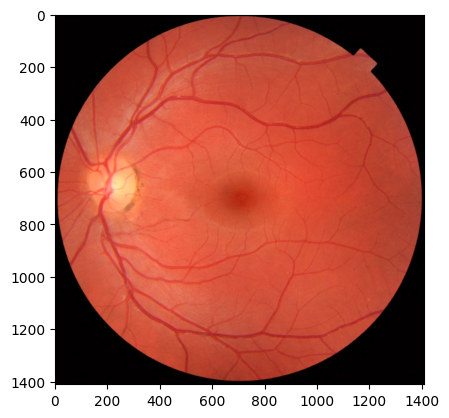

In [ ]:
plt.imshow(data.retina())

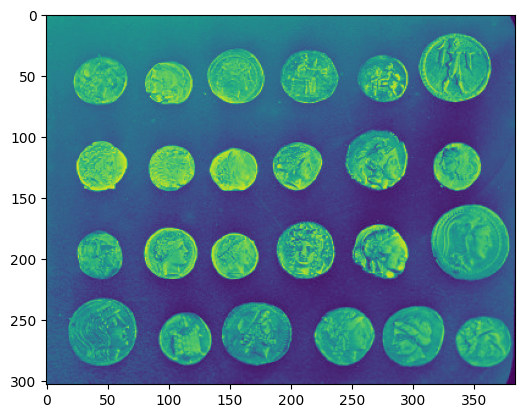

In [ ]:
plt.imshow(data.coins())

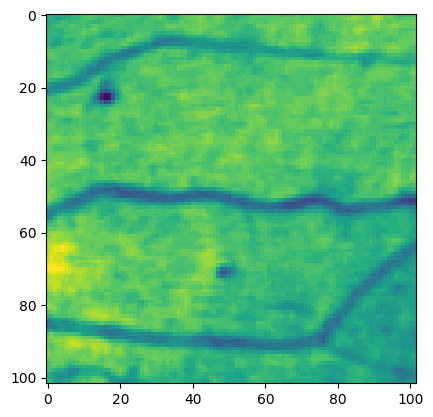

In [ ]:
plt.imshow(data.microaneurysms())

## Galeria de imagens de exemplo

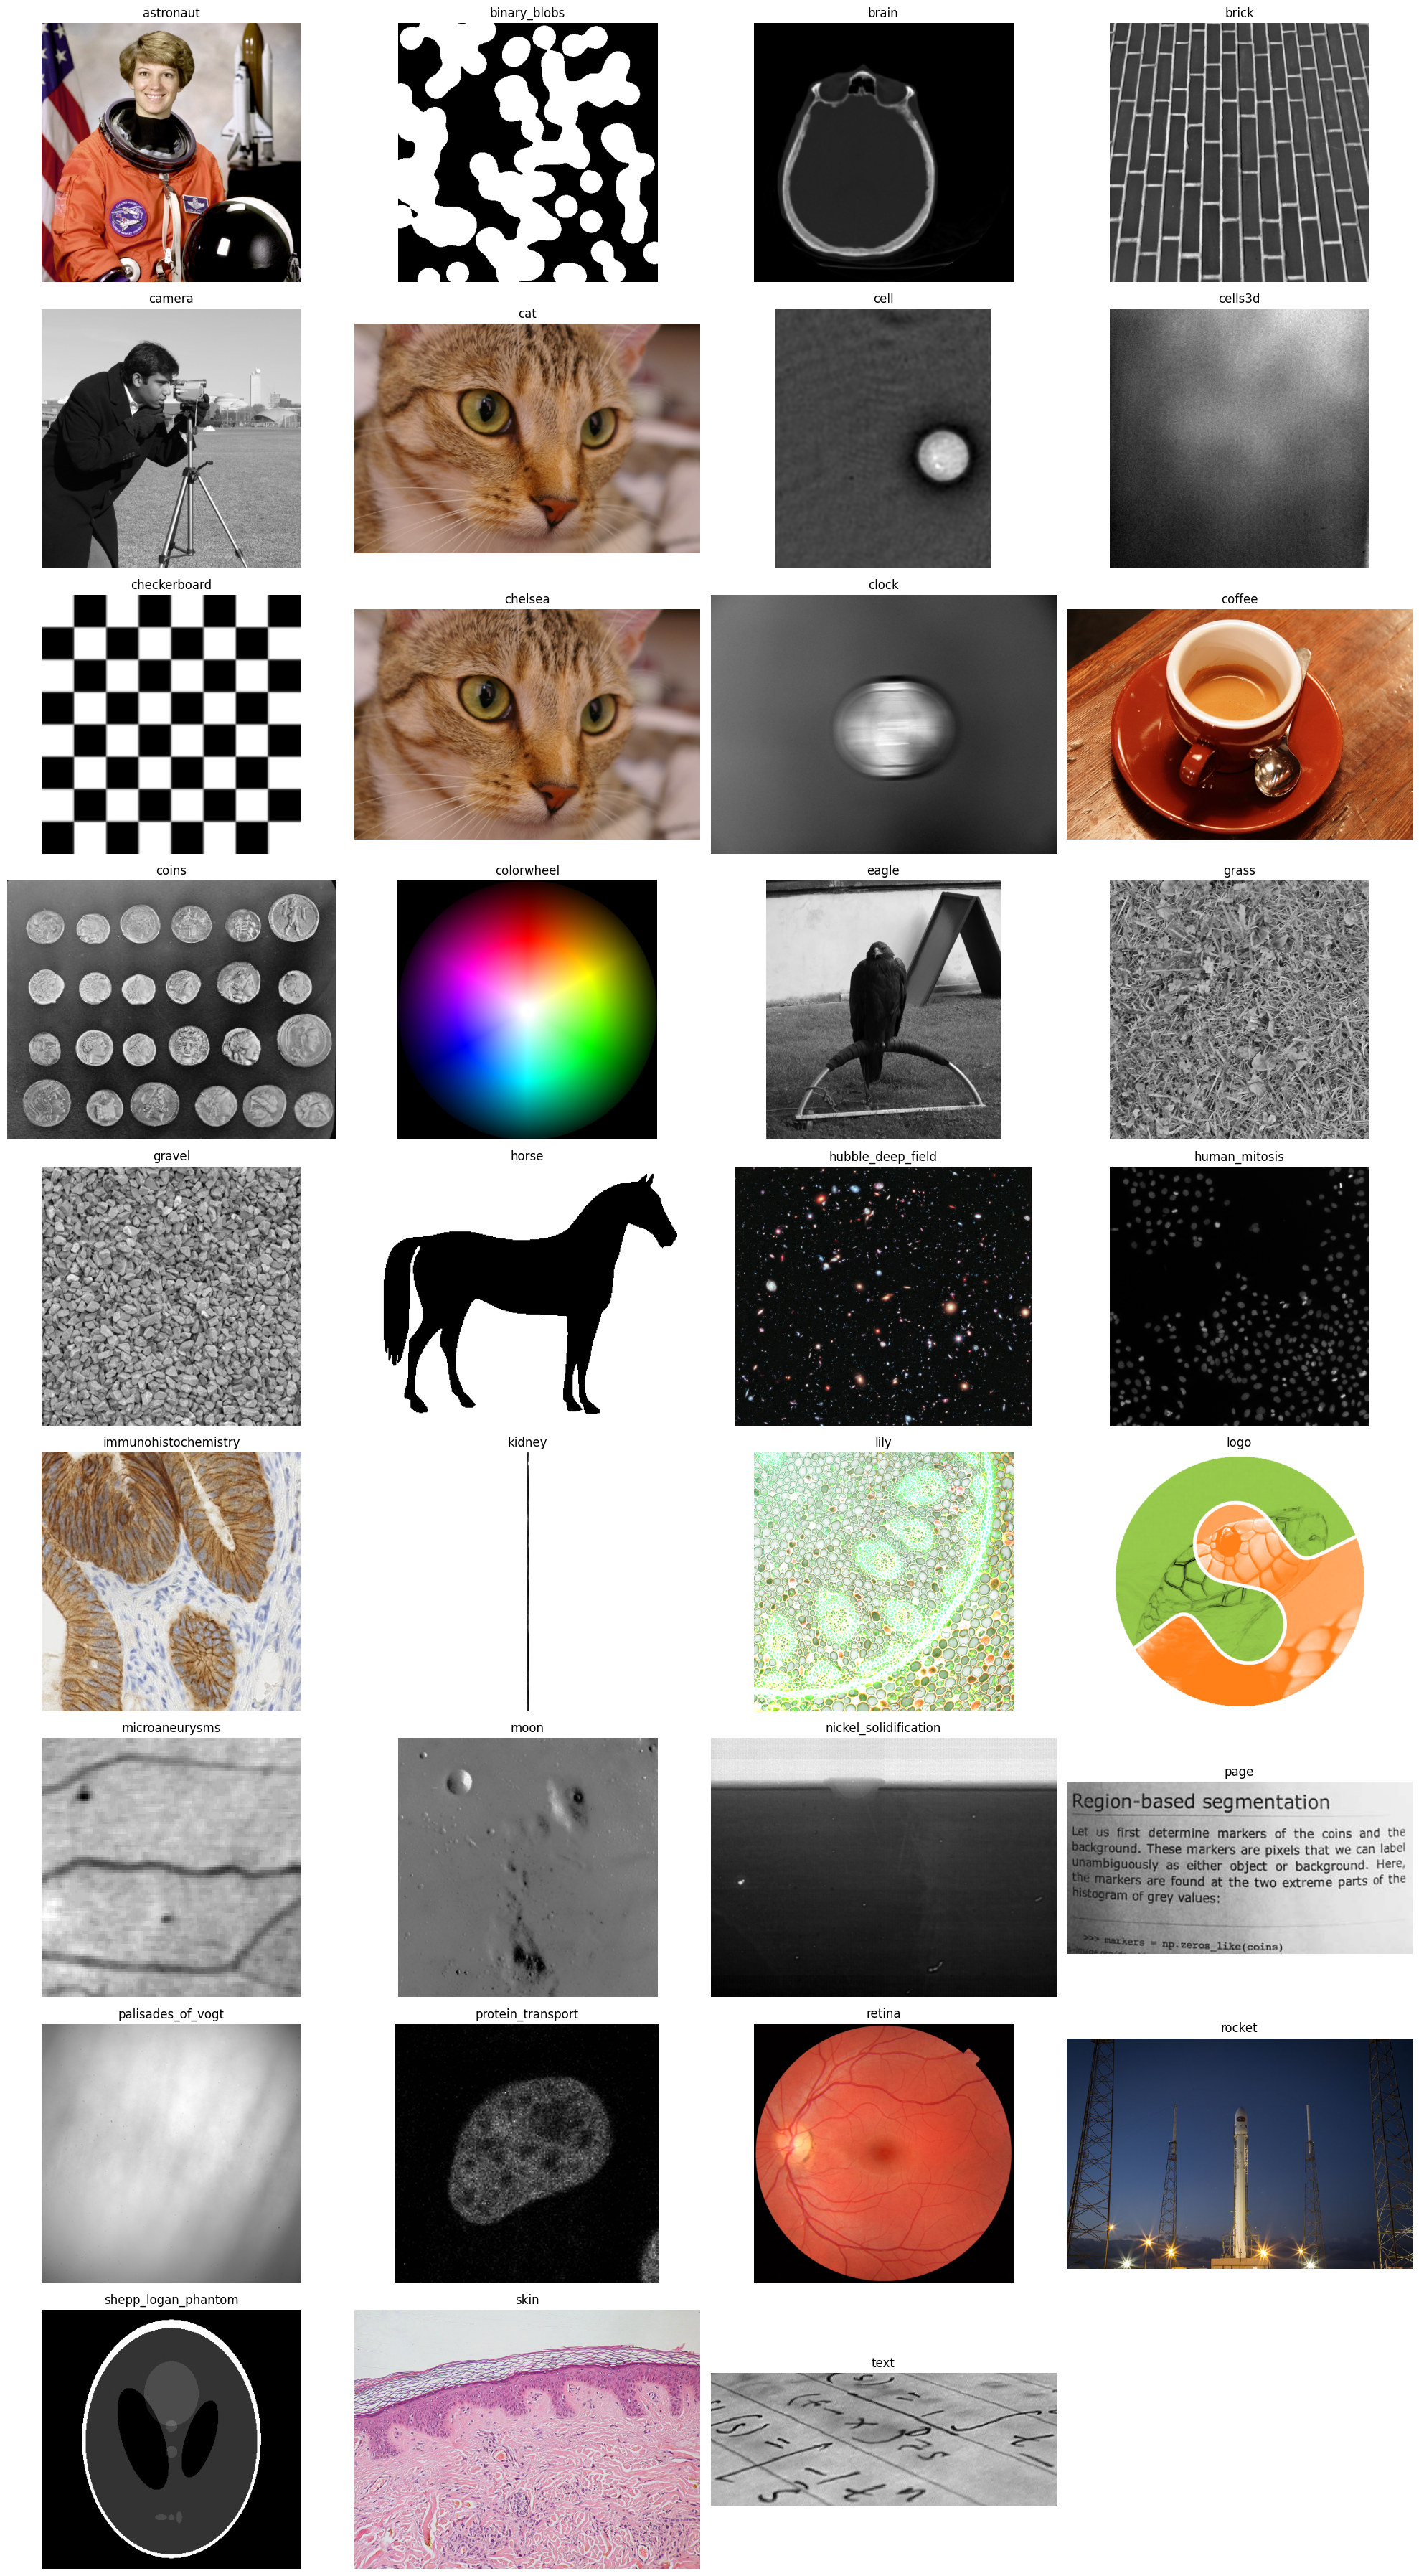

In [ ]:
import inspect
import matplotlib.pyplot as plt
from skimage import data

image_functions = []
for name, func in inspect.getmembers(data, inspect.isfunction):
    if name in ['lbp_frontal_face_scenario', 'lfw_subset']:
        continue
    try:
        img = func()
        # Se for um array numpy, vamos ajustar ou validar as dimensões
        if hasattr(img, 'ndim'):
            # Se for 3D mas não for RGB/RGBA (ex: volumes como 'brain' ou 'cells3d')
            if img.ndim == 3 and img.shape[-1] not in [3, 4]:
                # Pegamos apenas a primeira fatia para visualização 2D
                img = img[0]
            elif img.ndim > 3:
                # Se tiver mais dimensões, tentamos reduzir para 2D pegando fatias
                img = img[0]
                while img.ndim > 2:
                    img = img[0]

            if img.ndim in [2, 3]:
                image_functions.append((name, img))
    except Exception:
        pass

# Plotar todas as imagens encontradas de forma segura
num_images = len(image_functions)
cols = 4
rows = (num_images + cols - 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(20, 4 * rows))
axes = axes.ravel()

for i, (name, img) in enumerate(image_functions):
    cmap = 'gray' if img.ndim == 2 else None
    axes[i].imshow(img, cmap=cmap)
    axes[i].set_title(name, fontsize=12)
    axes[i].axis('off')

for j in range(i + 1, len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.show()

## Visualização de coleções volumétricas

Plotando todas as 10 fatias da coleção 'brain' (shape: (10, 256, 256)):


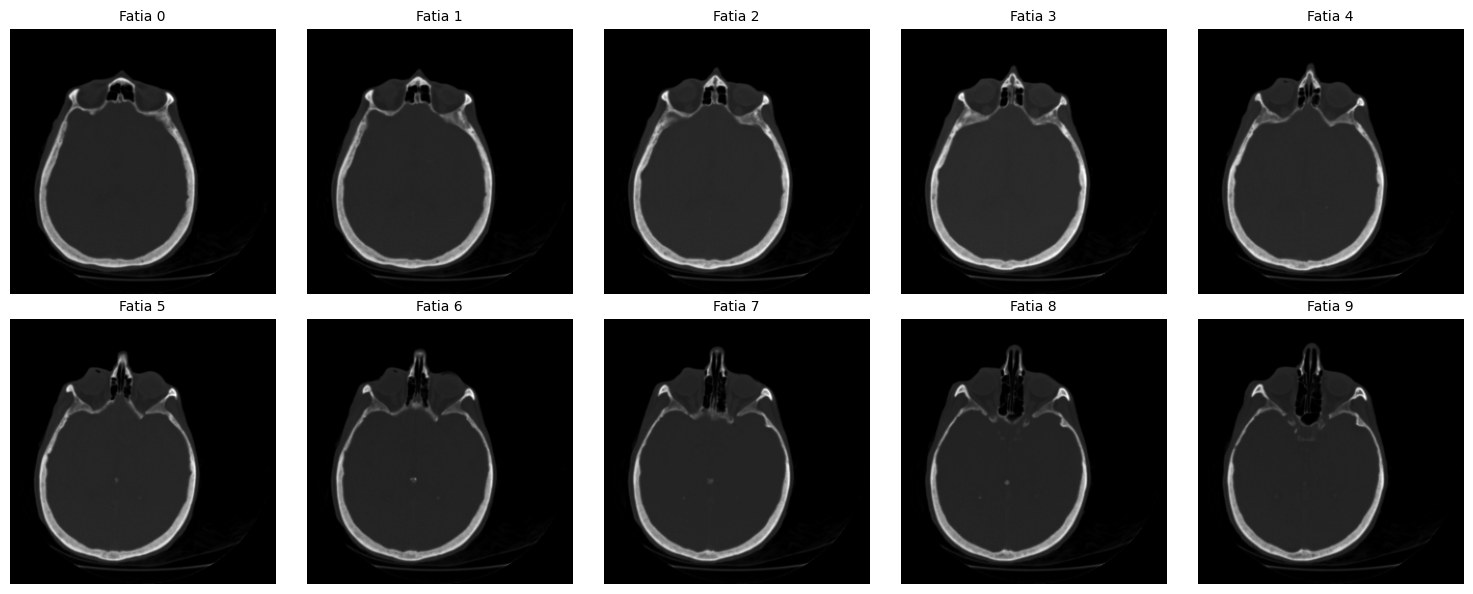

--------------------------------------------------------------------------------
Plotando todas as 11 fatias da coleção 'nickel_solidification' (shape: (11, 384, 512)):


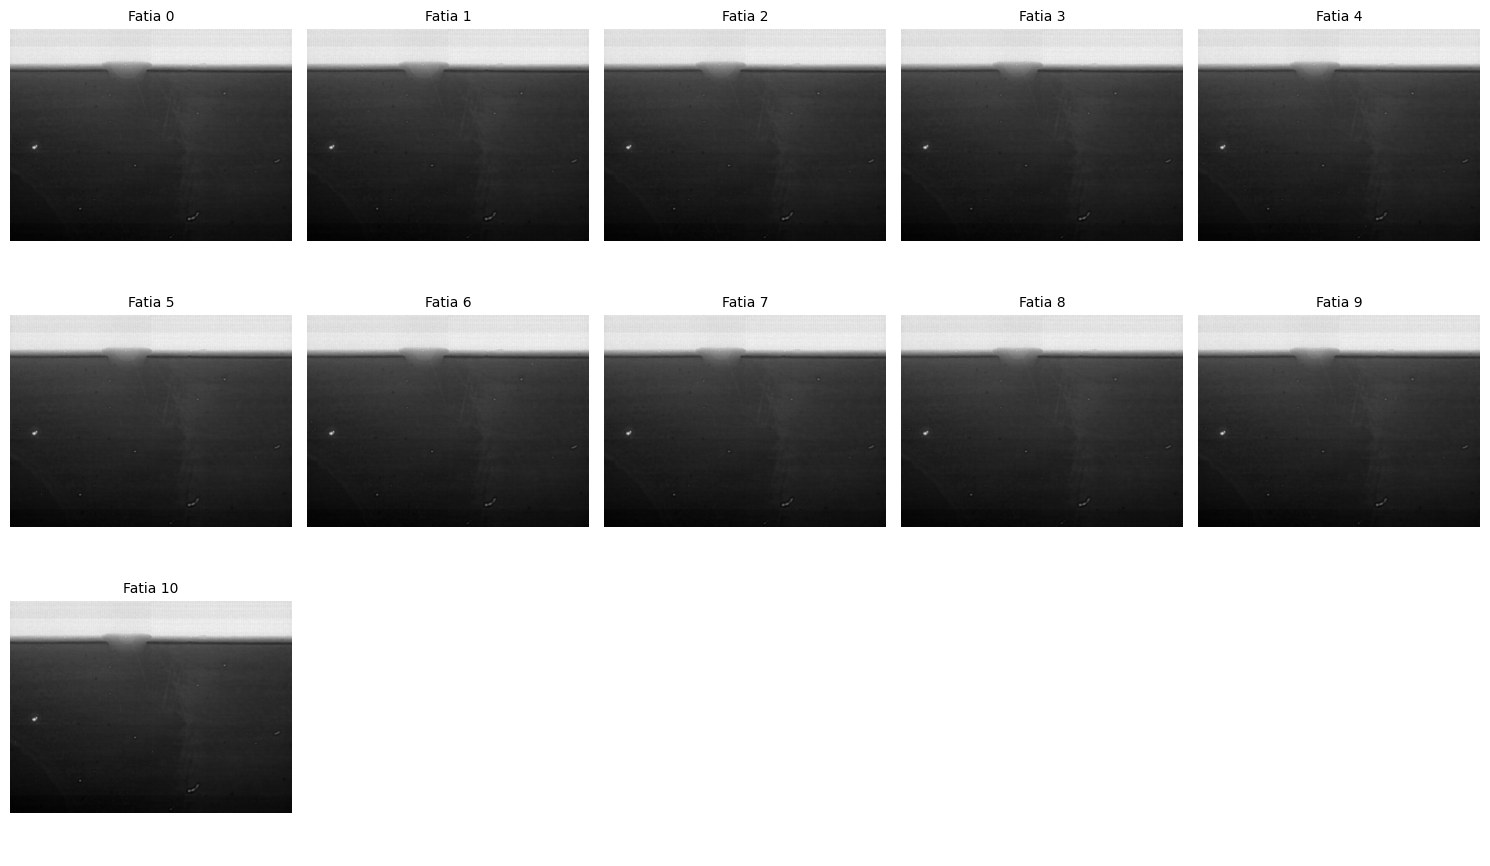

--------------------------------------------------------------------------------
Plotando todas as 60 fatias da coleção 'palisades_of_vogt' (shape: (60, 1440, 1440)):


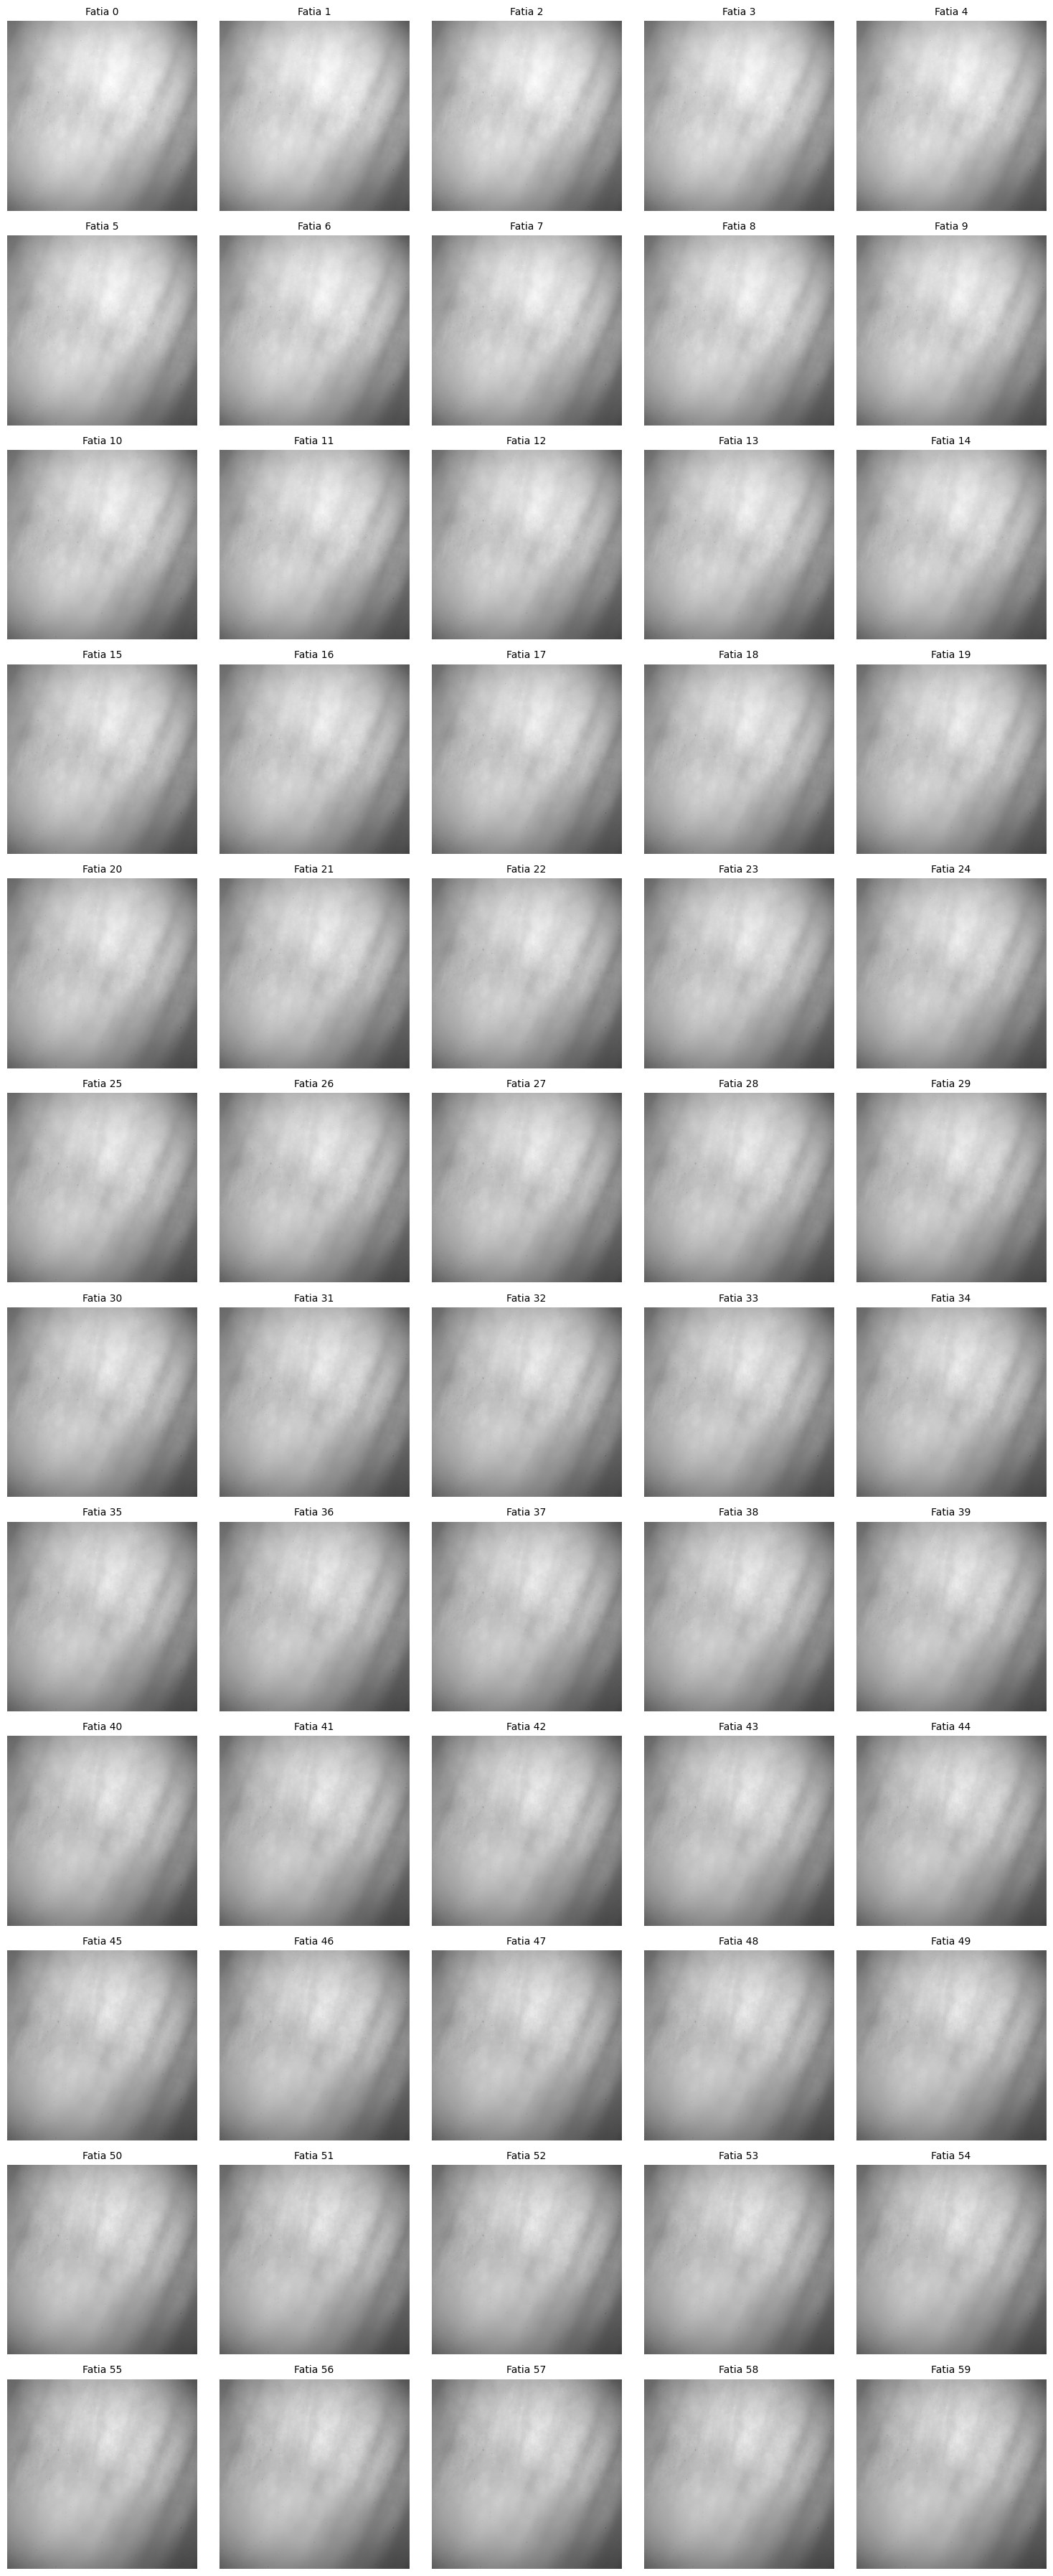

--------------------------------------------------------------------------------


In [ ]:
import inspect
import matplotlib.pyplot as plt
from skimage import data

# Filtrar e identificar especificamente datasets que possuem múltiplas fatias (coleções 3D)
collections = {}
for name, func in inspect.getmembers(data, inspect.isfunction):
    if name in ['lbp_frontal_face_scenario', 'lfw_subset']:
        continue
    try:
        img = func()
        # Se for um volume 3D e não for RGB padrão (não tem 3 ou 4 canais na última dimensão)
        if hasattr(img, 'ndim') and img.ndim == 3 and img.shape[-1] not in [3, 4]:
            collections[name] = img
    except Exception:
        pass

# Plotar as fatias de cada coleção encontrada
for col_name, volume in collections.items():
    num_slices = volume.shape[0]
    print(f"Plotando todas as {num_slices} fatias da coleção '{col_name}' (shape: {volume.shape}):")

    cols = 5
    rows = (num_slices + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(15, 3 * rows))
    axes = axes.ravel()

    for i in range(num_slices):
        axes[i].imshow(volume[i], cmap='gray')
        axes[i].set_title(f"Fatia {i}", fontsize=10)
        axes[i].axis('off')

    # Esconder eixos restantes
    for j in range(num_slices, len(axes)):
        axes[j].axis('off')

    plt.tight_layout()
    plt.show()
    print("-" * 80)

## Comparação de filtros espaciais

In [2]:
def implot(img, img_filt, nomefiltro, kernelsize):
    plt.figure(figsize=(10, 4))
    plt.subplot(1, 2, 1)
    plt.imshow(img)
    plt.title('Imagem original')
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.imshow(img_filt)
    plt.title(f'Filtro: {nomefiltro} ({kernelsize}×{kernelsize})')
    plt.axis('off')
    plt.tight_layout()
    plt.show()


/opt/pyvenv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


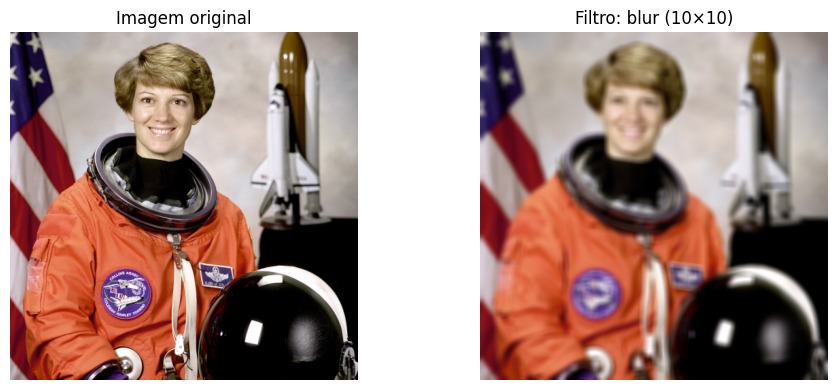

In [3]:
img = data.astronaut()

img_filt = cv2.blur(img, (10,10))
implot(img, img_filt, 'blur', '10')

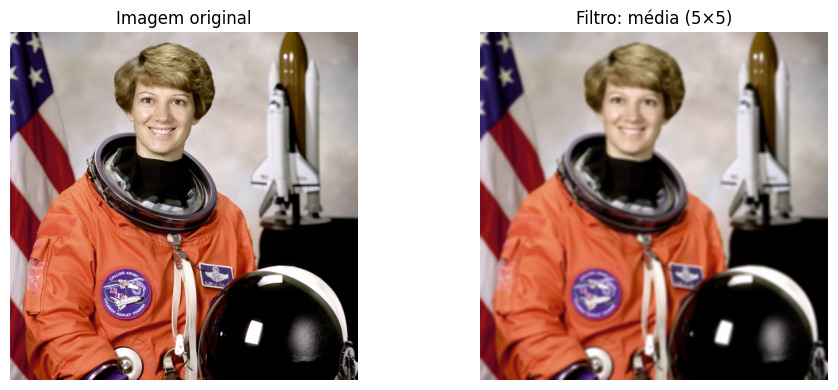

In [4]:
# Kernel de média 5×5: normalização evita saturação dos valores.
kernel = np.ones((5, 5), dtype=np.float32) / 25.0
img_filt = cv2.filter2D(img, -1, kernel)
implot(img, img_filt, 'média', 5)


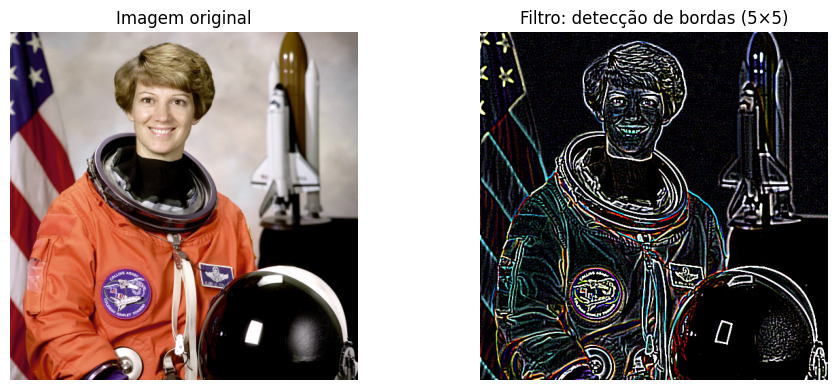

In [5]:
kernel = np.array([
    [-1, -1, -1, -1, -1],
    [-1,  1,  2,  1, -1],
    [-1,  2,  4,  2, -1],
    [-1,  1,  2,  1, -1],
    [-1, -1, -1, -1, -1]
])

img_filt = cv2.filter2D(img, -1, kernel)
implot(img, img_filt, 'detecção de bordas', '5')

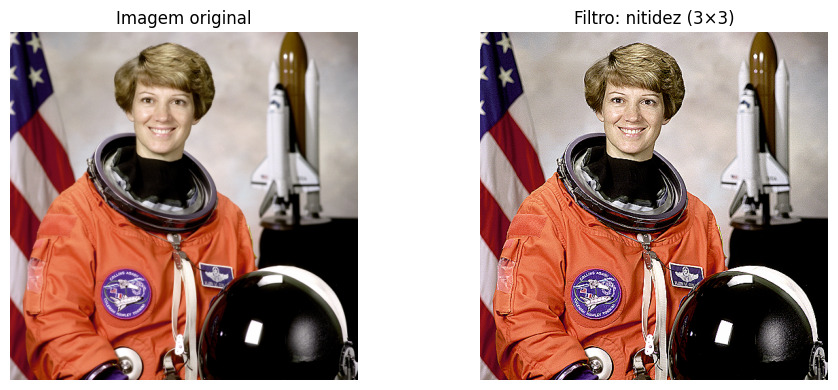

In [6]:
kernel = np.array([
    [0, -1, 0],
    [-1, 5, -1],
    [0, -1, 0]
    ]
)

img_filt = cv2.filter2D(img, -1, kernel)
implot(img, img_filt, 'nitidez', '3')

## Observações

- O filtro de média 5×5 usa pesos normalizados (soma = 1), evitando saturação causada pelo kernel original.
- O kernel 5×5 seguinte realça transições/bordas; o filtro 3×3 realiza realce de nitidez.
- A galeria e as coleções podem demandar memória e acesso aos dados disponibilizados pela scikit-image ao executar novamente.
